<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_G13_GEODISCOVERY_MASTER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS G13 — GeoDiscovery research engine

One restart-safe notebook from the raw 19-band GeoDAWN raster to geological interpretation, physics features, spatially honest benchmarks, fault-network reconstruction and a validated DrivenData GeoTIFF.

**How to use it**
1. Upload `g13_bundle.zip` to `MyDrive/GEMS_2/` (needed until the G13 code is on `main`).
2. Set `MODE` in the configuration cell. Start with `FAST_BASELINE` (CPU is enough): it writes `submission_g13_baseline.tif` within minutes.
3. Run every cell top to bottom. After a disconnect, run the bootstrap and engine cells again and continue: verified stages are reused, not recomputed.

| Mode | Stages |
|---|---|
| `FAST_BASELINE` | inventory → splits → raw model → S0 submission → DTI tournament → submission → report |
| `FEATURE_DISCOVERY` | + physics features, quality, geological EDA, regimes, S1 physics submission |
| `FULL_RESEARCH` | + ablations A0–A11, incomplete-label learning, optional U-Net, fusion / mixture of experts, topology, failure modes |
| `FINAL_SUBMISSION` | reuses saved models from Drive → tournament → validated champion GeoTIFF |

**Honesty rules built into the code:** labels never enter a feature; TEST geography is used once; every offline DTI is a *proxy* against withheld **known** faults, never the official score; no leaderboard number appears unless you type it in yourself (section 41).

## 01. Configuration and execution modes

In [1]:
MODE = 'FULL_RESEARCH'          # FAST_BASELINE | FEATURE_DISCOVERY | FULL_RESEARCH | FINAL_SUBMISSION
DRIVE_ROOT = '/content/drive/MyDrive/GEMS_2'
WORK_DIR = '/content/gems_g13_work'                       # fast local disk (features live here)
OUT_DIR = DRIVE_ROOT + '/outputs/G13_GEODISCOVERY'        # persistent mirror on Drive
REPO = 'mybenkhadda/GEMS---drivendata'
REF = 'main'
BUNDLE = DRIVE_ROOT + '/g13_bundle.zip'                   # G13 code overlay (skipped if main already has gems_bench/g13)

# Optional overrides (any G13Config key; a typo raises with the closest valid key)
OVERRIDES = dict(
    raw_path='', known_path='', template_path='',          # empty = discovered by content under DRIVE_ROOT
    dem_dir='',                                            # optional 100 m DEM-derived rasters on the template grid
    run_deep=False,                                        # tier-2 U-Net: set True on a GPU runtime (FULL_RESEARCH)
    # n_estimators=400, area_fracs=(0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12),
)
FORCE = ()                       # e.g. ('dti_opt', 'submission') to recompute stages

## 02. GitHub and environment initialization
Mounts Drive, clones `main`, overlays the G13 bundle if `gems_bench/g13` is not on `main` yet, installs only what Colab lacks (no PyTorch / CUDA reinstall), records the commit.

In [2]:
import os, sys, subprocess, zipfile, importlib
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
if not os.path.exists(CODE + '/.git'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', '-b', REF, f'https://github.com/{REPO}.git', CODE], check=True)
else:
    subprocess.run(['git', '-C', CODE, 'pull', '-q', '--ff-only'], check=False)
commit = subprocess.run(['git', '-C', CODE, 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
if not os.path.exists(CODE + '/gems_bench/g13/engine.py'):
    assert os.path.exists(BUNDLE), f'upload g13_bundle.zip to {BUNDLE}'
    with zipfile.ZipFile(BUNDLE) as z:
        z.extractall(CODE)
    print('G13 overlay extracted from', BUNDLE)
need = [p for p in ('xgboost', 'lightgbm', 'rasterio', 'skimage') if importlib.util.find_spec(p) is None]
if need:
    pip_names = {'skimage': 'scikit-image'}
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + [pip_names.get(p, p) for p in need], check=True)
if CODE not in sys.path:
    sys.path.insert(0, CODE)
os.chdir(CODE)
import warnings; warnings.filterwarnings('ignore')
print('commit', commit)

Mounted at /content/drive
commit a29bc2db910a382a318880268ee44473cd87a5fd


In [3]:
import json, numpy as np, pandas as pd
from pathlib import Path
from IPython.display import display, Image, Markdown
from gems_bench.g13 import G13_VERSION
from gems_bench.g13 import contracts as C
from gems_bench.g13.config import G13Config
from gems_bench.g13.engine import Engine

cfg = G13Config.from_mode(MODE, drive_root=DRIVE_ROOT, work_dir=WORK_DIR, out_dir=OUT_DIR,
                          force_stages=tuple(FORCE), **OVERRIDES)
eng = Engine(cfg)
W = Path(WORK_DIR)

def run(stage):
    """Run a stage only if it belongs to the selected mode (verified stages are reused)."""
    if stage not in cfg.active_stages():
        print(f'[{stage}] not part of mode {MODE}: skipped'); return None
    return eng.run_stage(stage)

def tbl(rel, n=20):
    p = W / rel
    if p.exists():
        df = pd.read_csv(p); display(df.head(n)); return df
    print('not available:', rel)

def fig(*names):
    idx = W / 'figures' / 'figure_index.csv'
    if not idx.exists(): return
    fi = pd.read_csv(idx).set_index('name')
    for n in names:
        if n in fi.index:
            display(Markdown(f"**{n}** — {fi.loc[n, 'takeaway']}")); display(Image(str(W / fi.loc[n, 'file'])))

print('G13', G13_VERSION, '| mode', MODE, '| stages:', cfg.active_stages())
display(pd.Series(C.hardware_report()))
eng.status()

G13 g13.1.0 | mode FULL_RESEARCH | stages: ('inventory', 'splits', 'features', 'quality', 'eda', 'regimes', 'baseline', 'ablation', 'pu_learning', 'deep', 'fusion', 'topology', 'dti_opt', 'failure_modes', 'submission', 'report')


,0
python,3.13.16
cpu_count,8
platform,Linux-6.6.159+-x86_64-with-glibc2.39
ram_gb,50.990276
ram_available_gb,49.120075
disk_free_gb,233.556
torch,2.14.1+cu130
cuda,True
gpu,Tesla T4
vram_gb,14.563171


,stage,complete,detail,seconds,summary
0,inventory,True,verified,6.942346,"{""fault_px"": 60894, ""fault_frac_valid"": 0.0117..."
1,splits,True,verified,26.445732,"{""test_fold"": 0, ""cv_folds"": [1, 2, 3], ""n_spl..."
2,features,False,missing output features/registry.csv,3598.727591,"{""n_features"": 297, ""by_family"": {""magnetic"": ..."
3,quality,True,verified,347.110474,"{""n"": 316, ""kept"": 283, ""rejected"": {""duplicat..."
4,eda,True,verified,2608.060552,"{""populations"": {""fault_corridor"": 20000, ""ran..."
5,regimes,True,verified,48.195217,"{""k"": 8, ""bgmm_effective_components"": 10, ""hdb..."
6,baseline,True,verified,1355.454548,"{""models"": [""S0_raw_xgboost"", ""S0_raw_lightgbm..."
7,ablation,False,no manifest,NaN,{}
8,pu_learning,False,no manifest,NaN,{}
9,deep,False,no manifest,NaN,{}


## 03–04. Input discovery, integrity checks and geophysical inventory
**Motivation:** nothing downstream is trustworthy without verified geometry. **Method:** the three official files are found by *content* (band descriptions, single integer band, same grid); CRS EPSG:32611, 100 m pixels and identical transforms are enforced (no silent reprojection). The raw cube is cached as a local memmap. **Outputs:** band inventory (coverage, quantiles, robust ranges, physical meaning, common-source flags), coverage matrix, figures. **Limitation:** physical units are not in the raster metadata; interpretations marked `inferred` should be checked against the organizers' data dictionary.

In [4]:
run('inventory')
print(json.dumps(eng.paths, indent=1))
tbl('inventory/band_inventory.csv', 19)
tbl('inventory/band_interpretation.csv', 19)
fig('inventory_coverage', 'inventory_coverage_matrix', 'valid_by_modality', 'raw_multiband_atlas')

[inventory] reused (verified)
{
 "raw": "/content/drive/MyDrive/GEMS_2/data/raw/geodawn/gems-geodawn-numerical-features.tif",
 "known": "/content/drive/MyDrive/GEMS_2/data/raw/faults/existing_faults.tif",
 "template": "/content/drive/MyDrive/GEMS_2/data/raw/example_submission.tif",
 "notes": [
  "G13 canonical metadata fix"
 ]
}


,band,name,modality,meaning,interpretation_status,common_source_of,finite_frac_in_template,missing_px_in_template,min,max,...,p25,p50,p75,p95,p99,p999,robust_range_p01_p99,iqr,n_unique_sample,units
0,1,mag_anom,magnetic,Magnetic anomaly (TMI minus a reference field),documented,tmi,0.999408,3061,-1052.004761,2.109448e+03,...,-113.790070,-57.687933,14.796303,162.736941,311.913668,5.856995e+02,600.475683,128.586372,206177,not documented in raster metadata
1,2,rtp,magnetic,Reduced-to-pole magnetic anomaly,documented,tmi,0.999408,3061,-2786.299561,4.508760e+03,...,-208.224560,-137.221664,-54.105858,153.745882,395.731045,1.036816e+03,854.484005,154.118702,205891,not documented in raster metadata
2,3,tmi_hg,magnetic,Horizontal gradient magnitude of TMI,documented,tmi,0.999408,3061,0.004910,2.200437e+03,...,5.603027,13.155465,31.134403,93.851629,189.227953,4.178563e+02,188.567161,25.531375,206050,not documented in raster metadata
3,4,geod_2ndinv,geodetic,Second invariant of geodetic strain rate,inferred,NaN,0.999408,3061,1.200000,8.745342e+01,...,5.900000,19.907789,33.000000,46.200001,57.773652,8.160366e+01,56.021885,27.100000,78271,not documented in raster metadata
4,5,iso_grav_anom_slope,gravity,Slope (gradient magnitude) of isostatic gravity,inferred,iso_grav_anom,0.999408,3061,0.001383,6.517290e-01,...,0.062606,0.102185,0.160493,0.270353,0.367849,4.934344e-01,0.351980,0.097887,205817,not documented in raster metadata
5,6,tc,magnetic,Undocumented magnetic-family band (grouped wit...,inferred,NaN,0.999405,3073,2.953424,8.856654e+01,...,15.201588,18.481700,21.509364,25.582316,29.100453,3.331004e+01,21.378154,6.307776,204321,not documented in raster metadata
6,7,geod_shearrate,geodetic,Geodetic shear strain rate,inferred,NaN,0.999408,3061,0.000000,5.440000e+01,...,0.700000,9.700000,17.500000,29.143348,38.500000,4.939896e+01,38.500000,16.800000,63037,not documented in raster metadata
7,8,geod_dilaterate,geodetic,Geodetic dilatation rate,inferred,NaN,0.999408,3061,-16.500000,3.452448e+01,...,3.000000,5.500000,9.026658,19.200001,27.000000,3.050000e+01,36.500000,6.026658,74111,not documented in raster metadata
8,9,tmi_vg,magnetic,Vertical gradient of TMI,documented,tmi,0.999408,3061,-7.650597,2.051092e+01,...,-0.056319,-0.008997,0.045143,0.319166,0.793537,2.029492e+00,1.485757,0.101462,206372,not documented in raster metadata
9,10,deq_n100a15,seismicity,Earthquake density (name suggests 100-neighbou...,inferred,NaN,0.999408,3061,0.000000,4.962515e+06,...,349.000000,622.799988,1685.199951,8631.383301,50237.199219,2.049906e+06,50118.899216,1336.199951,43023,not documented in raster metadata


,name,meaning,status,fault_mechanism,alternatives,scale,noise,modality
0,mag_anom,Magnetic anomaly (TMI minus a reference field),documented,Juxtaposition of rocks with different magnetis...,"Lithological contacts, intrusions, volcanic fl...",0.5-20 km; deeper sources broader,Line-levelling and survey-boundary steps,magnetic
1,rtp,Reduced-to-pole magnetic anomaly,documented,"Centres anomalies over sources, so gradients s...",Remanence breaks the RTP assumption and shifts...,0.5-20 km,RTP amplifies N-S noise at low inclination (mo...,magnetic
2,tmi_hg,Horizontal gradient magnitude of TMI,documented,Maxima over steep contacts,"Any contact, not only faults",0.2-5 km,Amplifies short-wavelength noise; common sourc...,magnetic
3,geod_2ndinv,Second invariant of geodetic strain rate,inferred,Regional deformation localisation,Interpolation of sparse GNSS,tens of km (context only),Very smooth,geodetic
4,iso_grav_anom_slope,Slope (gradient magnitude) of isostatic gravity,inferred,As iso_grav_anom_hg,Any density contact,1-10 km,Common source with iso_grav_anom,gravity
5,tc,Undocumented magnetic-family band (grouped wit...,inferred,Unknown until documented,Unknown,Unknown,Unknown,magnetic
6,geod_shearrate,Geodetic shear strain rate,inferred,Walker Lane shear zones,Interpolation,tens of km,Very smooth,geodetic
7,geod_dilaterate,Geodetic dilatation rate,inferred,Extensional domains,Interpolation,tens of km,Very smooth,geodetic
8,tmi_vg,Vertical gradient of TMI,documented,Sharpens shallow sources; zero crossings near ...,"Shallow lithology, culture",0.2-3 km,Strong noise amplification,magnetic
9,deq_n100a15,Earthquake density (name suggests 100-neighbou...,inferred,Active seismogenic structures,"Catalogue completeness, swarms, induced events",~15 km kernel (context),Catalogue bias,seismicity


## 18 (run early). Geographic and whole-fault validation design
Geographic folds (20 km blocks, 13 km embargo) via `gems_bench.folds`; one fold is the **untouched TEST** partition; selection is cross-fitted on the CV folds; stacking uses out-of-fold predictions. Discovery splits withhold whole fault *systems* (linked within 1 km) from supervision and score them with retained faults masked **pixel-exactly** and their predictions ignored (`disc_official`, the hidden-test analogue). The audit checks disjointness, embargo distance, withheld-label leakage and fault components crossing boundaries.

In [5]:
run('splits')
tbl('splits/audit.csv')
fig('validation_design')

[splits] reused (verified)


,partition,train_px,val_px,train_pos,val_pos,train_val_overlap,train_test_overlap,min_train_to_val_km,min_train_to_test_km,fault_components_crossing_train_val,note,withheld_px,eval_px,retained_in_eval_px,withheld_in_test_px,supervised_withheld_px,n_systems,test_fold
0,cv1,1802905.0,1410378.0,23638.0,14910.0,0.0,0.0,13.0,13.000385,0.0,crossing components are split by the embargo b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cv2,1990887.0,1150307.0,21740.0,16086.0,0.0,0.0,13.0,13.000000,0.0,crossing components are split by the embargo b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cv3,1857628.0,1225880.0,23535.0,14079.0,0.0,0.0,13.0,13.100000,1.0,crossing components are split by the embargo b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,disc0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5205.0,1436076.0,13681.0,0.0,0.0,38.0,NaN
4,disc1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5313.0,940310.0,8259.0,0.0,0.0,22.0,NaN
5,disc2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5309.0,1083874.0,11781.0,0.0,0.0,25.0,NaN
6,test,NaN,1377747.0,NaN,15819.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


## 12–17. Physics-informed feature engineering
Families: **magnetic / gravity** (FFT derivatives, THD, tilt, tilt gradient, analytic signal, upward continuation 0.5–4 km and residuals, normalised source strength, multiscale gradient / coherence / Hessian, monogenic local phase and phase congruency, entropy), **conductivity, depth, terrain** (slope, slope breaks, ridge / valley strength, relief anisotropy, TPI), **directional** (oriented log-Gabor), **structural** (cross-contact asymmetry, orientation persistence, characteristic scale), **cross-modal** (axial alignment, joint edges, discordance, shifted cross-correlation and lag, agreement fraction; common-source pairs flagged), **regional normalisation**, **validity** (boundary distance, local coverage). All label-free, mask-aware, stored as robust-scaled memmaps. In `FAST_BASELINE` only the validity family is built. Expect ~10–30 min of CPU for all families on the full grid.

[features] running (missing output features/registry.csv)
[features] magnetic: 51 features in 422.9s
[features] gravity: 51 features in 413.9s
[features] conductivity: 21 features in 163.4s
[features] depth: 22 features in 155.4s
[features] terrain: 31 features in 192.8s
[features] directional: 30 features in 409.2s
[features] structural: 30 features in 718.9s
[features] cross_modal: 45 features in 781.5s
[features] regional_norm: 10 features in 104.0s
[features] validity: 6 features in 3.0s
[features] complete in 3386.1s; 2 outputs; 3 files persisted


,n,mb,seconds
family,,,
conductivity,21,491.835983,159.491
cross_modal,45,1053.934250,772.799
depth,22,515.256744,151.523
directional,30,702.622833,403.309
gravity,51,1194.458817,404.774
magnetic,51,1194.458817,413.616
regional_norm,10,234.207611,102.302
structural,30,702.622833,713.324
terrain,31,726.043594,187.320


**feature_atlas** — 8 representative physics features

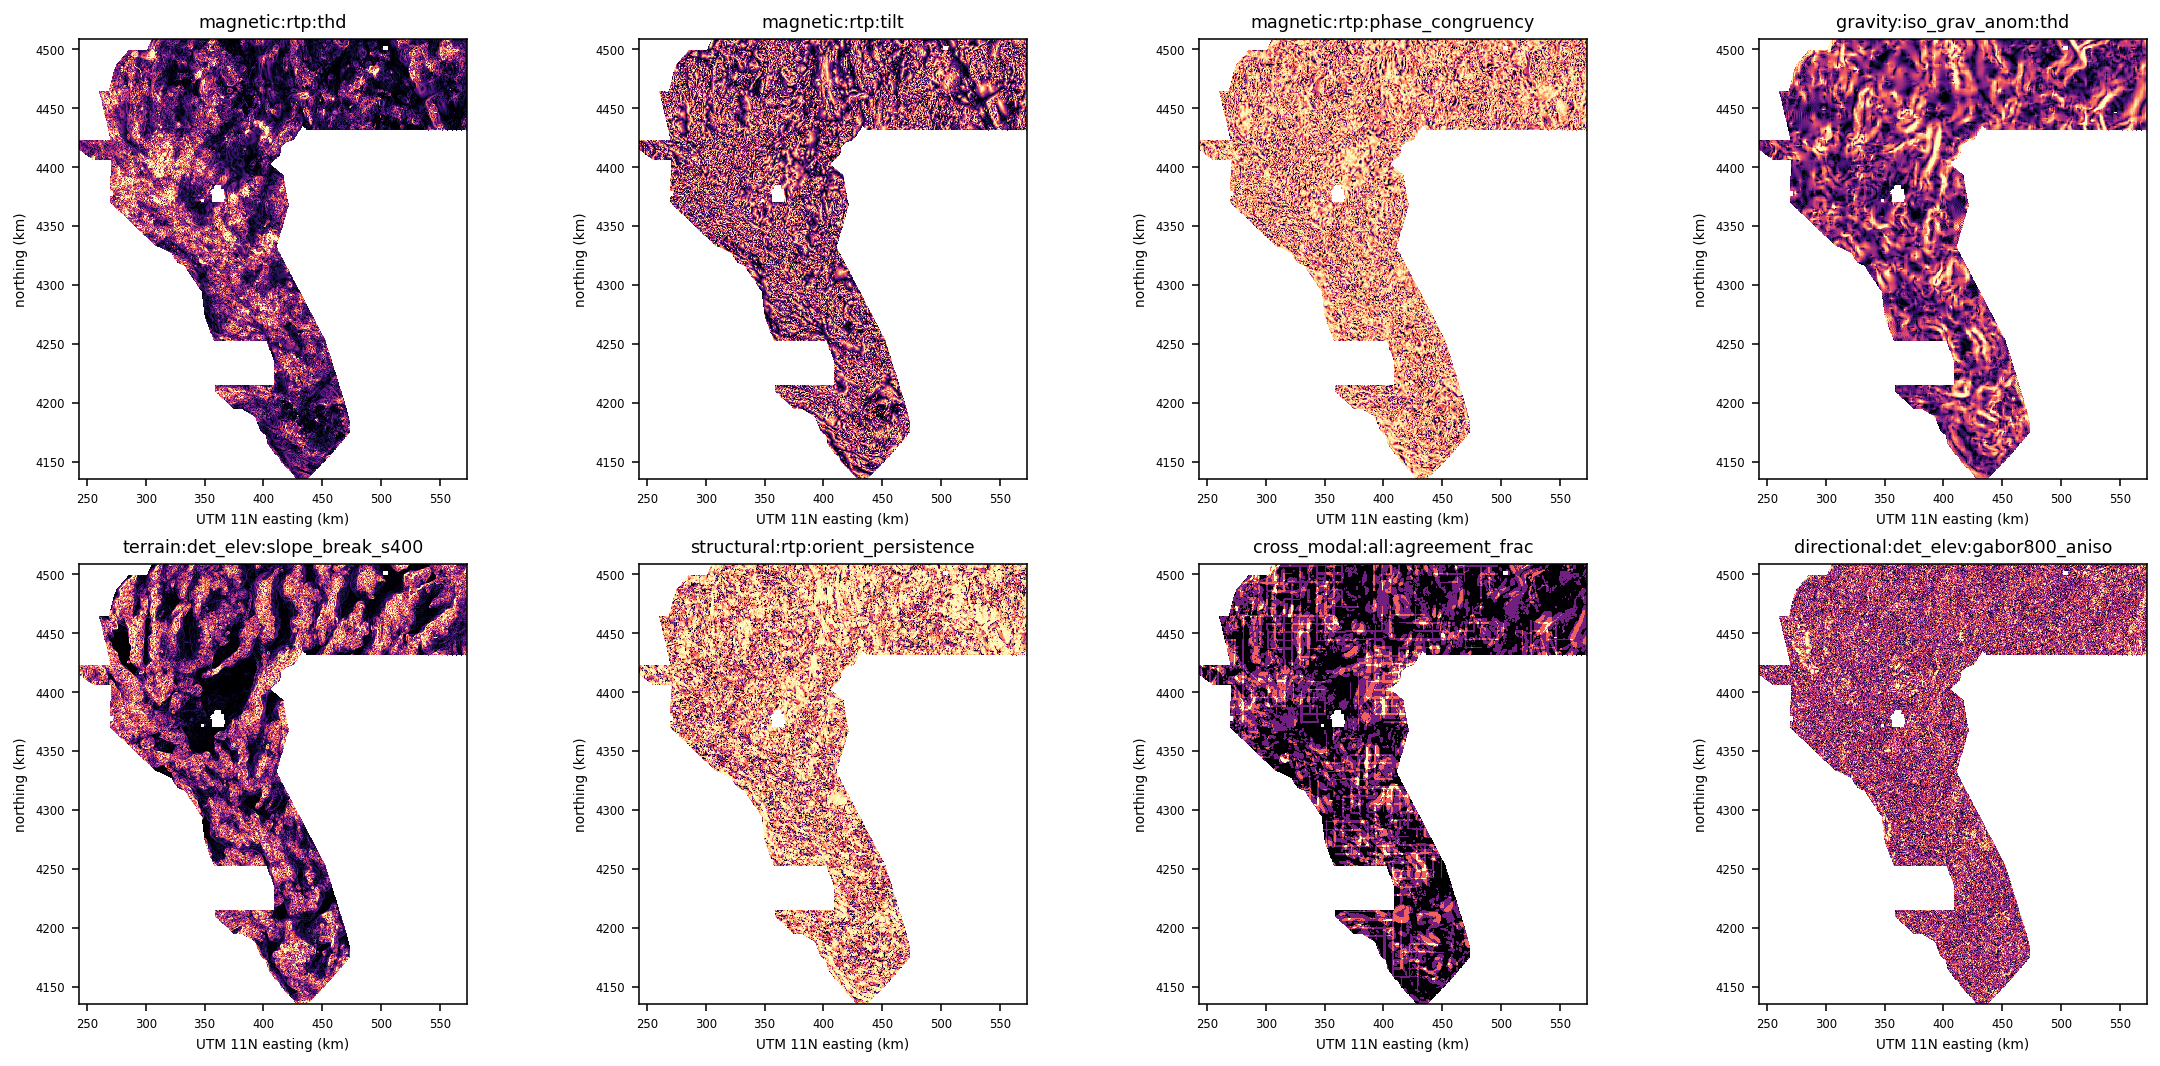

In [6]:
run('features')
reg = eng.store.registry
if len(reg):
    display(reg.groupby('family').agg(n=('name', 'size'), mb=('bytes', lambda b: b.sum() / 2**20), seconds=('seconds', 'sum')))
fig('feature_atlas')

## 18–19. Feature quality, redundancy and the geological feature registry
Coverage, finite fraction, variance, nodata-boundary dependence, smoothing sensitivity, train/validation shift (KS), redundancy clusters (|Spearman| ≥ 0.98), runtime and storage. Rejections carry an explicit reason; raw bands are never rejected.

In [7]:
run('quality')
q = tbl('quality/feature_quality.csv', 10)
if q is not None:
    print('kept', int(q.kept.sum()), 'of', len(q)); display(q.reject_reason.value_counts())

[quality] reused (verified)


,feature,family,finite_frac_sample,variance,dynamic_range_p01_p99,n_unique,coverage_frac,seconds,storage_mb,modality,boundary_dependence,shift_ks_mean,scale_m,common_source,smoothing_sensitivity,reject_reason,cluster,kept
0,raw:mag_anom,raw,1.0,1.424281e+04,599.620954,19997,0.999408,0.0,0.0,raw,0.001209,0.141667,NaN,NaN,NaN,NaN,137,True
1,raw:rtp,raw,1.0,2.796248e+04,858.070135,19992,0.999408,0.0,0.0,raw,0.012174,0.167400,NaN,NaN,NaN,NaN,141,True
2,raw:tmi_hg,raw,1.0,1.759756e+03,192.702996,19993,0.999408,0.0,0.0,raw,0.010717,0.158667,NaN,NaN,NaN,NaN,239,True
3,raw:geod_2ndinv,raw,1.0,2.318905e+02,56.257016,7313,0.999408,0.0,0.0,raw,0.025323,0.591133,NaN,NaN,NaN,NaN,220,True
4,raw:iso_grav_anom_slope,raw,1.0,5.967703e-03,0.349803,19996,0.999408,0.0,0.0,raw,0.020156,0.069133,NaN,NaN,NaN,NaN,6,True
5,raw:tc,raw,1.0,1.960007e+01,21.496784,19974,0.999405,0.0,0.0,raw,0.026426,0.074000,NaN,NaN,NaN,NaN,157,True
6,raw:geod_shearrate,raw,1.0,9.932530e+01,38.599998,4339,0.999408,0.0,0.0,raw,0.025811,0.657600,NaN,NaN,NaN,NaN,221,True
7,raw:geod_dilaterate,raw,1.0,4.138867e+01,36.900000,6501,0.999408,0.0,0.0,raw,0.001802,0.454800,NaN,NaN,NaN,NaN,158,True
8,raw:tmi_vg,raw,1.0,6.484273e-02,1.487016,19998,0.999408,0.0,0.0,raw,0.018970,0.083600,NaN,NaN,NaN,NaN,268,True
9,raw:deq_n100a15,raw,1.0,2.469464e+10,50120.799217,4985,0.999408,0.0,0.0,raw,0.025313,0.578667,NaN,NaN,NaN,NaN,222,True


kept 283 of 316


,count
reject_reason,
duplicate;,19
degenerate;,8
nodata_boundary;duplicate;,4
nodata_boundary;,2


## 05–11. Geological EDA: multiscale statistics, fault-conditioned contrasts, cross-fault profiles, directional analysis
Computed on the CV region only (TEST untouched). Contrasts compare the fault corridor with **several control populations** (random, matched 1–3 km, high-gradient, ridge / drainage, magnetic and gravity lineaments without mapped faults, nodata boundaries), with Cliff's delta, spatial-block bootstrap intervals, overlap, mutual information vs a permutation baseline, and fold sign stability. A feature is `discriminative` only if it survives every control; `confounded` if it only separates faults from flat background. Unmapped pixels are unlabeled, not fault-free. Profiles: strike-normal transects (±5 km) clustered into response families.

In [8]:
run('eda')
s = tbl('eda/discriminative_summary.csv', 25)
if s is not None: display(s.verdict.value_counts())
tbl('eda/scale_space_auc.csv', 40); tbl('eda/correlation_lengths.csv')
fig('scale_space_auc', 'directional_variograms', 'radial_power_spectra', 'fault_conditioned_contrasts',
    'cross_fault_profiles', 'orientation_roses')

[eda] reused (verified)


,feature,family,cd_random,cd_min_abs,cd_matched,cd_high_grad,stable,ci_excludes_zero,verdict
0,cross_modal:terr_dept:joint_edge,cross_modal,0.237896,0.165701,0.165701,0.200353,1.000000,True,discriminative
1,terrain:det_elev:valley_s3200,terrain,0.227284,0.128683,0.128683,0.415001,1.000000,True,discriminative
2,terrain:det_elev:tpi_s20,terrain,-0.224855,0.166865,-0.166865,-0.485135,1.000000,True,discriminative
3,terrain:det_elev:valley_s1600,terrain,0.218248,0.165896,0.165896,0.296061,1.000000,True,discriminative
4,directional:iso_grav_anom:gabor3200_energy,directional,0.215000,0.050391,0.094435,0.321097,0.666667,False,confounded
5,terrain:det_elev:slope_break_s800,terrain,0.203807,0.046298,0.118482,-0.234708,0.666667,False,partly_confounded
6,terrain:det_elev:slope_s3200,terrain,0.195010,0.093215,0.106798,-0.219752,1.000000,True,partly_confounded
7,terrain:det_elev:slope_break_s1600,terrain,0.193617,0.065079,0.065079,-0.130933,1.000000,False,confounded
8,raw:ieq_n100a15,raw,0.191343,0.095735,0.095735,0.121151,0.666667,False,confounded
9,terrain:det_elev:slope_s1600,terrain,0.190874,0.055701,0.127451,-0.325175,1.000000,False,partly_confounded


,count
verdict,
weak,249
confounded,41
discriminative,13
partly_confounded,13


,band,scale_m,gradient_auc
0,rtp,100,0.544268
1,rtp,200,0.544994
2,rtp,400,0.547362
3,rtp,800,0.550920
4,rtp,1600,0.551097
5,rtp,3200,0.545354
6,rtp,6400,0.520636
7,iso_grav_anom,100,0.558578
8,iso_grav_anom,200,0.558575
9,iso_grav_anom,400,0.558386


,direction,corr_length_km,nugget_ratio,band
0,E-W,12.8,0.007799,rtp
1,N-S,12.8,0.006442,rtp
2,NE-SW,12.8,0.012082,rtp
3,NW-SE,12.8,0.014908,rtp
4,E-W,12.8,0.000208,iso_grav_anom
5,N-S,12.8,0.000140,iso_grav_anom
6,NE-SW,12.8,0.000325,iso_grav_anom
7,NW-SE,12.8,0.000373,iso_grav_anom
8,E-W,12.8,0.001780,det_elev
9,N-S,12.8,0.001561,det_elev


## 20–21. Geological regimes and fault archetypes
Clusters of geophysical signatures (never coordinates), fitted on CV training pixels: MiniBatch K-Means across k with seed-stability (ARI), silhouette and GMM BIC; Bayesian GMM and HDBSCAN for comparison. The k rule is fixed in advance. Archetypes are empirical signal categories of mapped-fault pixels (joint magnetic–gravity, strong magnetic, strong gravity, terrain-visible, buried without terrain, weak persistent, weak) with model recall per archetype once a model exists.

In [9]:
run('regimes')
tbl('regimes/regime_selection.csv'); tbl('regimes/regime_atlas.csv'); tbl('regimes/archetypes.csv')
fig('geological_regimes')

[regimes] reused (verified)


,k,kmeans_ari_mean,kmeans_silhouette,gmm_bic
0,3,0.439758,0.154547,314236.556254
1,4,0.352358,0.133242,308897.555419
2,5,0.501625,0.149135,306369.544512
3,6,0.444318,0.142707,304645.303609
4,7,0.452942,0.153732,301844.847649
5,8,0.522695,0.136436,300611.221362
6,9,0.505285,0.130050,299876.289971
7,10,0.409449,0.117136,298216.318611


,regime,area_km2,area_frac,fault_density_cv,spatial_coherence,median_rtp,median_iso_grav_anom,median_det_elev,median_cond_surf,median_depth_to_base_surf
0,0,10817.28,0.209462,0.014690,0.486813,-181.585037,-8.471231,-109.074036,2.661280,349.102417
1,1,4748.60,0.091950,0.013665,0.469358,101.227875,-4.988636,69.815613,2.889901,250.287399
2,2,10438.72,0.202132,0.012702,0.488329,-145.339081,-6.355612,-137.344254,3.054411,319.258850
3,3,7426.99,0.143814,0.013301,0.486417,-147.315567,-5.349178,-58.901260,2.871049,212.115601
4,4,1171.57,0.022686,0.005894,0.496449,-165.237885,-28.873325,-204.499710,2.940174,3282.555664
5,5,1492.62,0.028903,0.014623,0.459263,-57.074490,-6.828588,51.473660,2.855181,438.731934
6,6,6172.50,0.119522,0.010558,0.494093,-152.170090,-20.385181,-198.937134,2.936329,1352.103271
7,7,9374.84,0.181531,0.009185,0.478916,-113.122589,-1.781077,261.279907,2.944009,39.986725


,archetype,n_px,share,recall_w_geo1,recall_w_geo2,recall_w_geo3
0,joint_magnetic_gravity,1685,0.039606,0.329586,0.042441,0.000000
1,strong_magnetic,11490,0.270073,0.248338,0.338402,0.235253
2,strong_gravity,8034,0.188840,0.348759,0.333333,0.166667
3,terrain_visible,6321,0.148576,0.352777,0.000000,0.037037
4,buried_no_terrain,2100,0.049361,0.190783,0.000000,0.000000
5,weak_persistent,8390,0.197208,0.273946,0.000000,0.119526
6,weak,4524,0.106337,0.257124,0.000000,0.000000


## 25. Raw baseline and **early submission (milestone S0)**
Tier-1 XGBoost (LightGBM too in research modes) on the raw bands: out-of-fold maps on CV folds, one map per discovery split (withheld systems removed, ignore ring weight 0), and a submission model trained on the whole CV region (TEST excluded). `submission_g13_baseline.tif` is written and validated **here**, before any deep learning, clustering or topology. If physics features exist, the physics model and `submission_g13_physics.tif` (S1) follow.

In [10]:
run('baseline')
board = tbl('tables/scoreboard.csv')
for f in ('submission_g13_baseline', 'submission_g13_physics'):
    p = W / 'submissions' / f'{f}.json'
    if p.exists():
        v = json.loads(p.read_text())['validation']
        print(f"{f}.tif  valid={v['valid']}  failed={v['checks_failed']}  positive_px={v['positive_px']}  Drive: {OUT_DIR}/submissions/{f}.tif")

[baseline] reused (verified)


,model,geo_proxy_dti,geo_zone_min,geo_optimism,geo_frac,geo_proxy_dti_continuous,disc_proxy_dti,disc_zone_min,disc_optimism,disc_frac,...,kind,strategy,n_features,disc_proxy_dti_ci_lo,disc_proxy_dti_ci_hi,test_reserved,cv1_predict_s,cv2_predict_s,cv3_predict_s,full_predict_s
0,S0_raw_xgboost,0.087291,0.083348,0.000000,0.12,0.050813,0.020546,0.019308,0.000000,0.12,...,xgboost,standard,19,0.014256,0.026873,True,1.731207,0.816920,1.109994,3.700898
1,S0_raw_lightgbm,0.088104,0.081984,0.000000,0.12,0.045650,0.016145,0.014773,0.000000,0.12,...,lightgbm,standard,19,0.011391,0.021905,True,28.632642,24.341279,25.671458,101.380045
2,S1_physics_all_xgboost,0.130796,0.116478,0.002508,0.08,0.065277,0.049031,0.047901,0.000137,0.12,...,xgboost,standard,316,0.036493,0.061154,True,21.355776,17.608327,18.315546,89.489661


submission_g13_baseline.tif  valid=True  failed=[]  positive_px=612411  Drive: /content/drive/MyDrive/GEMS_2/outputs/G13_GEODISCOVERY/submissions/submission_g13_baseline.tif
submission_g13_physics.tif  valid=True  failed=[]  positive_px=612411  Drive: /content/drive/MyDrive/GEMS_2/outputs/G13_GEODISCOVERY/submissions/submission_g13_physics.tif


## 26–27. Feature-family ablations, interactions and compact selection
A0 raw → A1–A8 single families → A9 all → A10 compact (importance + quality) → A11 complementary families; targeted interactions (magnetic × gravity, magnetic × terrain, gravity × depth, conductivity × terrain, structural × cross-modal, structural × directional) with interaction = DTI(A+B) − DTI(A) − DTI(B) + DTI(raw). Identical splits, sampling and models. Paired spatial-block bootstrap against raw-only with Holm correction. This is the most expensive CPU stage (~7 fits per experiment); a GPU runtime makes XGBoost much faster.

[ablation] running (no manifest)
[model] A0_raw_xgboost: done (cv1_fit_s=3s, cv1_predict_s=1s, cv2_fit_s=3s, cv2_predict_s=0s, cv3_fit_s=2s, cv3_predict_s=0s, disc0_fit_s=3s, disc1_fit_s=4s, disc2_fit_s=3s)
[model] A1_magnetic_xgboost: done (cv1_fit_s=6s, cv1_predict_s=3s, cv2_fit_s=6s, cv2_predict_s=2s, cv3_fit_s=5s, cv3_predict_s=2s, disc0_fit_s=9s, disc1_fit_s=8s, disc2_fit_s=8s)
[model] A2_gravity_xgboost: done (cv1_fit_s=5s, cv1_predict_s=3s, cv2_fit_s=5s, cv2_predict_s=2s, cv3_fit_s=5s, cv3_predict_s=2s, disc0_fit_s=9s, disc1_fit_s=9s, disc2_fit_s=9s)
[model] A3_conductivity_xgboost: done (cv1_fit_s=4s, cv1_predict_s=1s, cv2_fit_s=3s, cv2_predict_s=1s, cv3_fit_s=3s, cv3_predict_s=1s, disc0_fit_s=5s, disc1_fit_s=6s, disc2_fit_s=5s)
[model] A4_terrain_xgboost: done (cv1_fit_s=4s, cv1_predict_s=2s, cv2_fit_s=4s, cv2_predict_s=2s, cv3_fit_s=4s, cv3_predict_s=2s, disc0_fit_s=7s, disc1_fit_s=7s, disc2_fit_s=7s)
[model] A5_depth_xgboost: done (cv1_fit_s=4s, cv1_predict_s=1s, cv2_fit_s=4

,model,geo_proxy_dti,geo_zone_min,geo_optimism,geo_frac,geo_proxy_dti_continuous,disc_proxy_dti,disc_zone_min,disc_optimism,disc_frac,...,kind,strategy,n_features,disc_proxy_dti_ci_lo,disc_proxy_dti_ci_hi,test_reserved,cv1_predict_s,cv2_predict_s,cv3_predict_s,full_predict_s
0,A10_compact_xgboost,0.127530,0.108961,2.008665e-03,0.08,0.068510,0.054561,0.052091,0.000000e+00,0.05,...,xgboost,standard,40,0.037395,0.073370,True,1.323280,1.060040,1.140005,5.844761
1,A9_all_xgboost,0.132277,0.126566,-2.775558e-17,0.08,0.066004,0.050278,0.049333,0.000000e+00,0.12,...,xgboost,standard,316,0.037883,0.062529,True,13.777090,11.004051,11.520105,54.465029
2,A11_complementary_xgboost,0.133072,0.114368,1.519197e-03,0.08,0.068046,0.049579,0.040874,4.956281e-04,0.12,...,xgboost,standard,228,0.036056,0.062721,True,9.873979,8.174946,8.473070,40.437342
3,S1_physics_all_xgboost,0.130796,0.116478,2.508121e-03,0.08,0.065277,0.049031,0.047901,1.374169e-04,0.12,...,xgboost,standard,316,0.036493,0.061154,True,21.355776,17.608327,18.315546,89.489661
4,A9_all_lightgbm,0.132486,0.125606,2.035145e-03,0.08,0.060189,0.046729,0.046271,0.000000e+00,0.12,...,lightgbm,standard,316,0.035071,0.059001,True,17.056771,14.069927,15.515911,66.530633
5,A4_terrain_xgboost,0.121337,0.113488,5.745400e-03,0.08,0.069735,0.045782,0.029580,9.264682e-04,0.12,...,xgboost,standard,50,0.034357,0.060819,NaN,1.795534,1.505326,1.542213,NaN
6,I_conductivity_x_terrain_xgboost,0.128353,0.125059,2.668339e-03,0.08,0.067182,0.044650,0.030781,2.584073e-04,0.12,...,xgboost,standard,71,0.033309,0.058858,NaN,2.695288,2.153628,2.339034,NaN
7,I_structural_x_directional_xgboost,0.119894,0.116001,1.583512e-03,0.08,0.062149,0.043660,0.039982,0.000000e+00,0.12,...,xgboost,standard,79,0.032842,0.055027,NaN,3.114561,2.454680,2.692186,NaN
8,I_magnetic_x_terrain_xgboost,0.127245,0.120584,1.997646e-03,0.08,0.066480,0.043624,0.035488,2.301603e-03,0.08,...,xgboost,standard,101,0.031861,0.057675,NaN,4.734652,3.843234,4.212346,NaN
9,I_structural_x_cross_xgboost,0.112408,0.111035,0.000000e+00,0.08,0.057585,0.040760,0.037510,0.000000e+00,0.12,...,xgboost,standard,94,0.030702,0.053017,NaN,3.439189,2.808891,2.967196,NaN


,model,delta,ci_lo,ci_hi,p_le_0,n_boot,p_holm
0,A1_magnetic_xgboost,0.004602,0.001800,0.007658,0.000000,300,0.0
1,A2_gravity_xgboost,-0.000124,-0.003055,0.002694,0.540000,300,1.0
2,A3_conductivity_xgboost,-0.000842,-0.003844,0.001461,0.760000,300,1.0
3,A4_terrain_xgboost,0.025236,0.017088,0.034635,0.000000,300,0.0
4,A5_depth_xgboost,0.000034,-0.002927,0.002646,0.453333,300,1.0
5,A6_structural_xgboost,0.017984,0.012648,0.024972,0.000000,300,0.0
6,A7_directional_xgboost,0.011459,0.006380,0.017476,0.000000,300,0.0
7,A8_cross_modal_xgboost,0.013281,0.007571,0.020307,0.000000,300,0.0
8,A9_all_xgboost,0.029732,0.019645,0.040067,0.000000,300,0.0
9,A10_compact_xgboost,0.034015,0.015698,0.049264,0.000000,300,0.0


,pair,dti_pair,dti_a,dti_b,dti_raw,interaction
0,A1_magnetic x A2_gravity,0.022490,0.025148,0.020422,0.020546,-0.002534
1,A1_magnetic x A4_terrain,0.043624,0.025148,0.045782,0.020546,-0.006760
2,A2_gravity x A5_depth,0.021068,0.020422,0.020581,0.020546,0.000612
3,A3_conductivity x A4_terrain,0.044650,0.019704,0.045782,0.020546,-0.000290
4,A6_structural x A8_cross_modal,0.040760,0.038531,0.033827,0.020546,-0.011052
5,A6_structural x A7_directional,0.043660,0.038531,0.032005,0.020546,-0.006329


**scoreboard_disc_proxy_dti** — Best disc_proxy_dti: A10_compact_xgboost (0.0546)

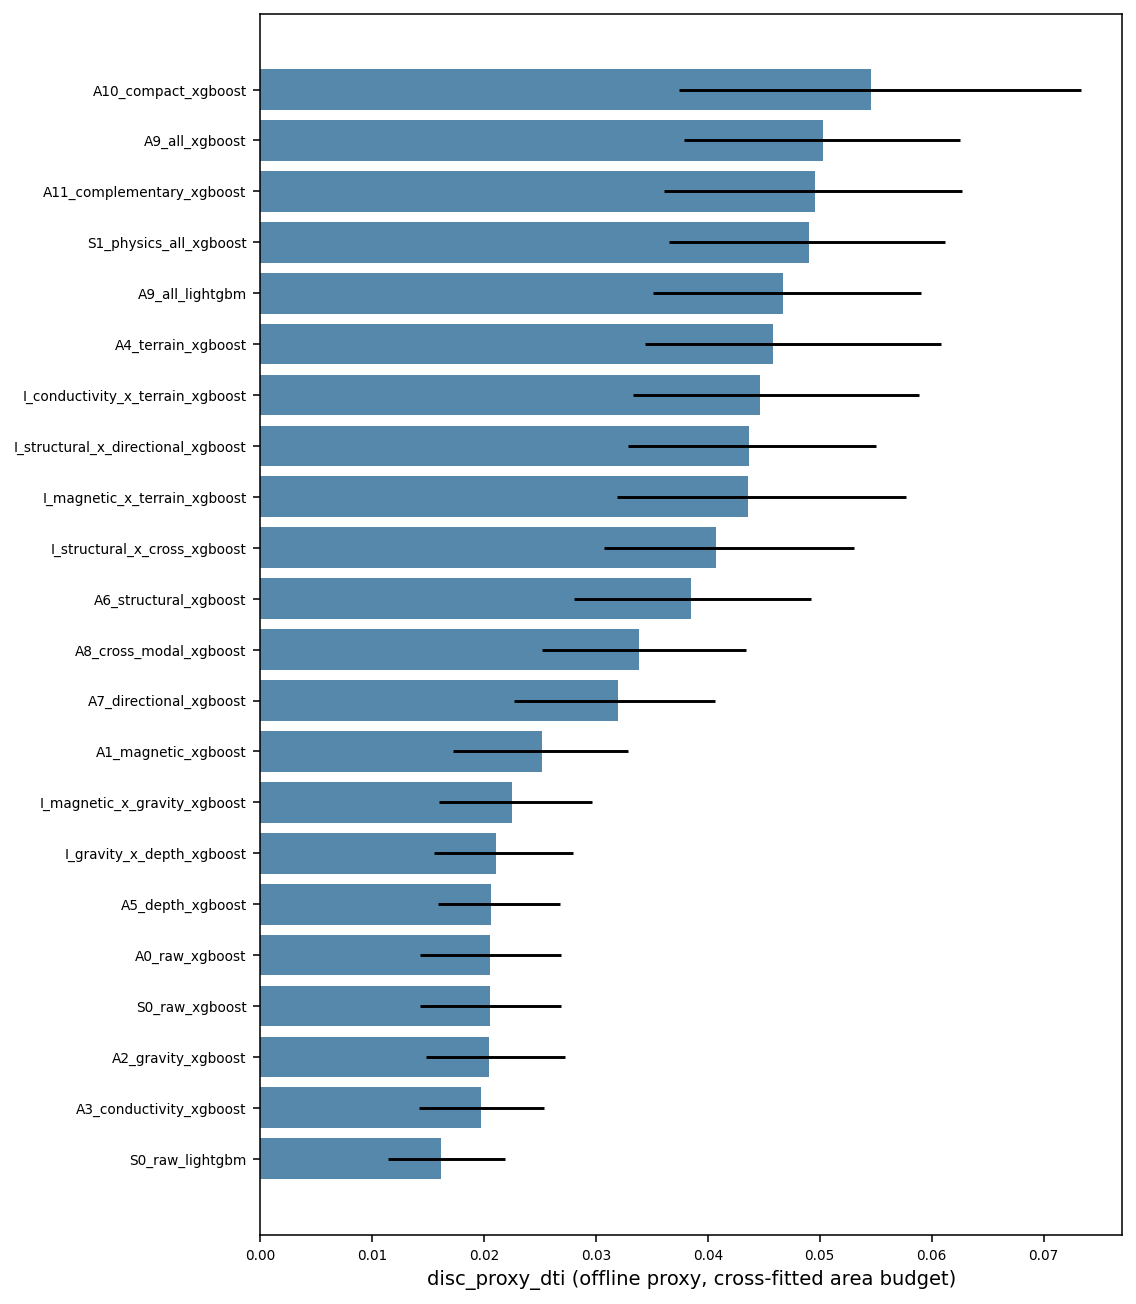

**scoreboard_geo_proxy_dti** — Best geo_proxy_dti: A11_complementary_xgboost (0.1331)

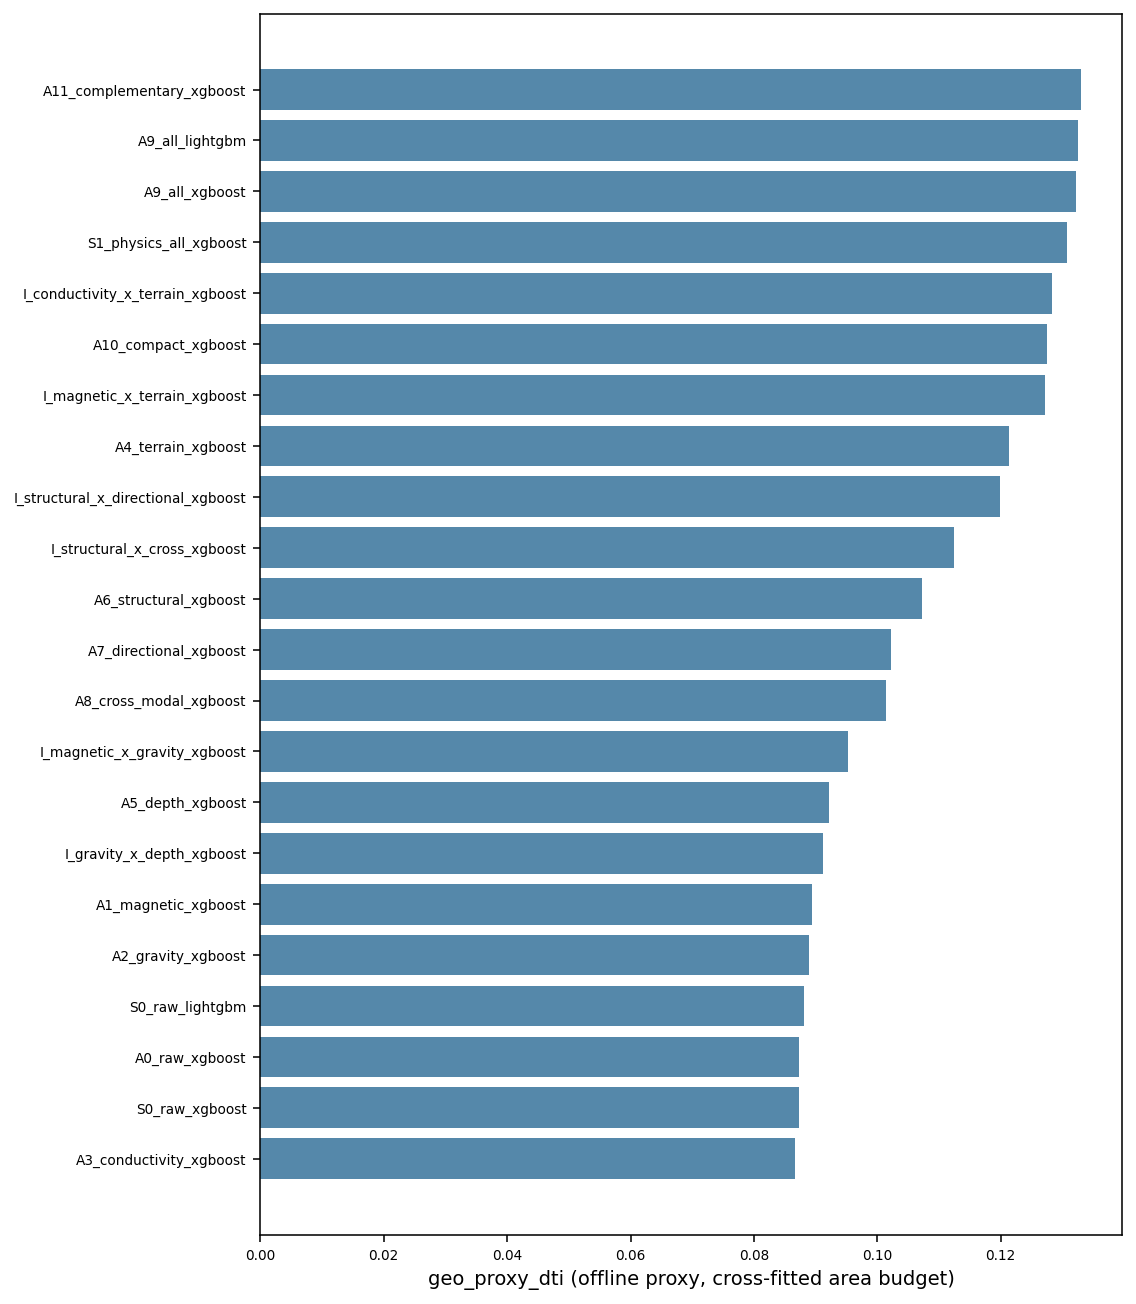

In [11]:
run('ablation')
tbl('ablation/ablation_rankings.csv', 30); tbl('ablation/paired_vs_raw.csv', 30); tbl('ablation/interactions.csv')
fig('scoreboard_disc_proxy_dti', 'scoreboard_geo_proxy_dti')

## 30. Incomplete labels: positive-unlabeled and hard-negative learning
Same features and model, four sampling strategies: standard, distance-stratified, soft negative weights rising with distance, and hard negatives from label-free confounders (ridges, drainages, strong potential-field edges, nodata boundaries) at weight 0.5. Compared with paired block bootstrap under identical validation.

In [12]:
run('pu_learning')
tbl('ablation/pu_vs_standard.csv')

[pu_learning] running (no manifest)
[model] PU_standard_xgboost: done (cv1_fit_s=4s, cv1_predict_s=1s, cv2_fit_s=4s, cv2_predict_s=1s, cv3_fit_s=4s, cv3_predict_s=1s, disc0_fit_s=6s, disc1_fit_s=5s, disc2_fit_s=5s)
[model] PU_distance_stratified_xgboost: done (cv1_fit_s=3s, cv1_predict_s=1s, cv2_fit_s=3s, cv2_predict_s=1s, cv3_fit_s=3s, cv3_predict_s=1s, disc0_fit_s=5s, disc1_fit_s=6s, disc2_fit_s=5s, full_fit_s=5s, full_predict_s=6s)
[model] PU_soft_negative_xgboost: done (cv1_fit_s=4s, cv1_predict_s=1s, cv2_fit_s=3s, cv2_predict_s=1s, cv3_fit_s=4s, cv3_predict_s=1s, disc0_fit_s=6s, disc1_fit_s=6s, disc2_fit_s=5s, full_fit_s=6s, full_predict_s=6s)
[model] PU_hard_negative_xgboost: done (cv1_fit_s=4s, cv1_predict_s=1s, cv2_fit_s=4s, cv2_predict_s=1s, cv3_fit_s=4s, cv3_predict_s=1s, disc0_fit_s=6s, disc1_fit_s=6s, disc2_fit_s=6s, full_fit_s=7s, full_predict_s=6s)
[pu_learning] complete in 288.6s; 1 outputs; 418 files persisted


,strategy,delta,ci_lo,ci_hi,p_le_0,n_boot
0,distance_stratified,-0.000134,-0.008821,0.006442,0.470000,300
1,soft_negative,-0.018424,-0.026972,-0.009742,1.000000,300
2,hard_negative,-0.006511,-0.011509,-0.001329,0.996667,300


,strategy,delta,ci_lo,ci_hi,p_le_0,n_boot
0,distance_stratified,-0.000134,-0.008821,0.006442,0.470000,300
1,soft_negative,-0.018424,-0.026972,-0.009742,1.000000,300
2,hard_negative,-0.006511,-0.011509,-0.001329,0.996667,300


## 29. Optional deep learning (tier 2/3): multitask residual U-Net
Heads: buffered fault probability (BCE + soft Tversky α=0.2/β=0.8), centre line, axial orientation, distance proxy, junctions; dilated bottleneck. Training tiles lie entirely inside the unit's training mask; Hann-blended inference. Compared with a single-head variant; the simpler model is kept unless multitask wins on held-out DTI. Runs only with `run_deep=True` and torch available (use a GPU runtime).

In [13]:
run('deep')
b = tbl('tables/scoreboard.csv', 50)
if b is not None: display(b[b.model.str.startswith('DL_')])

[deep] running (no manifest)
[deep] complete in 0.0s; 0 outputs; 419 files persisted


,model,geo_proxy_dti,geo_zone_min,geo_optimism,geo_frac,geo_proxy_dti_continuous,disc_proxy_dti,disc_zone_min,disc_optimism,disc_frac,...,kind,strategy,n_features,disc_proxy_dti_ci_lo,disc_proxy_dti_ci_hi,test_reserved,cv1_predict_s,cv2_predict_s,cv3_predict_s,full_predict_s
0,S0_raw_xgboost,0.087291,0.083348,0.000000e+00,0.12,0.050813,0.020546,0.019308,0.000000e+00,0.12,...,xgboost,standard,19,0.014256,0.026873,True,1.731207,0.816920,1.109994,3.700898
1,S0_raw_lightgbm,0.088104,0.081984,0.000000e+00,0.12,0.045650,0.016145,0.014773,0.000000e+00,0.12,...,lightgbm,standard,19,0.011391,0.021905,True,28.632642,24.341279,25.671458,101.380045
2,S1_physics_all_xgboost,0.130796,0.116478,2.508121e-03,0.08,0.065277,0.049031,0.047901,1.374169e-04,0.12,...,xgboost,standard,316,0.036493,0.061154,True,21.355776,17.608327,18.315546,89.489661
3,A0_raw_xgboost,0.087291,0.083348,0.000000e+00,0.12,0.050813,0.020546,0.019308,0.000000e+00,0.12,...,xgboost,standard,19,0.014256,0.026873,NaN,0.620404,0.442986,0.484022,NaN
4,A1_magnetic_xgboost,0.089430,0.086017,0.000000e+00,0.12,0.049928,0.025148,0.020767,0.000000e+00,0.12,...,xgboost,standard,70,0.017235,0.032834,NaN,2.773644,2.223787,2.316224,NaN
5,A2_gravity_xgboost,0.088958,0.079791,5.376068e-04,0.12,0.049595,0.020422,0.018184,0.000000e+00,0.12,...,xgboost,standard,70,0.014801,0.027245,NaN,2.619024,2.441472,2.418760,NaN
6,A3_conductivity_xgboost,0.086710,0.078604,0.000000e+00,0.12,0.048857,0.019704,0.018608,0.000000e+00,0.12,...,xgboost,standard,40,0.014189,0.025389,NaN,1.367698,1.070582,1.172487,NaN
7,A4_terrain_xgboost,0.121337,0.113488,5.745400e-03,0.08,0.069735,0.045782,0.029580,9.264682e-04,0.12,...,xgboost,standard,50,0.034357,0.060819,NaN,1.795534,1.505326,1.542213,NaN
8,A5_depth_xgboost,0.092229,0.080782,1.153297e-03,0.12,0.052333,0.020581,0.017797,0.000000e+00,0.12,...,xgboost,standard,41,0.015908,0.026739,NaN,1.321139,1.111315,1.159737,NaN
9,A6_structural_xgboost,0.107297,0.101436,9.073412e-04,0.12,0.054489,0.038531,0.034046,0.000000e+00,0.12,...,xgboost,standard,49,0.028053,0.049182,NaN,1.749175,1.559214,1.509671,NaN


,model,geo_proxy_dti,geo_zone_min,geo_optimism,geo_frac,geo_proxy_dti_continuous,disc_proxy_dti,disc_zone_min,disc_optimism,disc_frac,...,kind,strategy,n_features,disc_proxy_dti_ci_lo,disc_proxy_dti_ci_hi,test_reserved,cv1_predict_s,cv2_predict_s,cv3_predict_s,full_predict_s


## 23 & 31. Model disagreement and adaptive expert fusion
Magnetic, gravity and terrain experts are trained, then the best complementary experts are fused as per-zone ranks: rank mean, cross-fitted fixed weights, and a LightGBM gate on [expert ranks, regime, DEM / boundary reliability, coherence, cross-modal agreement, disagreement] trained on out-of-fold predictions only. The gate is kept only if it beats both simpler fusions. Disagreement regions are listed as candidates for review.

In [14]:
run('fusion')
tbl('fusion/fusion_scoreboard.csv'); tbl('fusion/disagreement_candidates.csv')

[fusion] running (no manifest)
[model] X_magnetic_expert_xgboost: done (cv1_fit_s=5s, cv1_predict_s=2s, cv2_fit_s=5s, cv2_predict_s=2s, cv3_fit_s=5s, cv3_predict_s=2s, disc0_fit_s=8s, disc1_fit_s=7s, disc2_fit_s=8s, full_fit_s=7s, full_predict_s=10s)
[model] X_gravity_expert_xgboost: done (cv1_fit_s=4s, cv1_predict_s=2s, cv2_fit_s=4s, cv2_predict_s=2s, cv3_fit_s=5s, cv3_predict_s=2s, disc0_fit_s=7s, disc1_fit_s=7s, disc2_fit_s=7s, full_fit_s=7s, full_predict_s=9s)
[model] X_terrain_expert_xgboost: done (cv1_fit_s=3s, cv1_predict_s=1s, cv2_fit_s=3s, cv2_predict_s=1s, cv3_fit_s=3s, cv3_predict_s=1s, disc0_fit_s=5s, disc1_fit_s=5s, disc2_fit_s=5s, full_fit_s=5s, full_predict_s=5s)
[fusion] complete in 439.7s; 3 outputs; 487 files persisted


,model,geo_proxy_dti,geo_zone_min,geo_optimism,geo_frac,geo_proxy_dti_continuous,disc_proxy_dti,disc_zone_min,disc_optimism,disc_frac,disc_proxy_dti_continuous,weights_all,kept
0,F_rank_mean,0.143126,0.126657,0.001947,0.08,0.072442,0.059316,0.045799,0.003370,0.05,0.029423,NaN,True
1,F_fixed_weights[geo],0.153887,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"(0.75, 0.25, 0.0)",True
2,F_fixed_weights[disc_official],NaN,NaN,NaN,NaN,NaN,0.085069,NaN,NaN,NaN,NaN,"(1.0, 0.0, 0.0)",True
3,F_gated_moe,0.144271,0.124951,0.002601,0.08,0.063413,0.071646,0.069022,0.003901,0.02,0.030432,NaN,False


,region,n_px,mean_disagreement,x_utm,y_utm
0,1869,27.0,0.375231,367662.962963,4.472733e+06
1,1866,8.0,0.349769,455025.000000,4.472725e+06
2,1568,36.0,0.347895,430708.333333,4.479714e+06
3,1872,4279.0,0.346909,366941.785464,4.468830e+06
4,1976,72.0,0.346559,306904.166667,4.468790e+06
5,2820,572.0,0.346530,334461.888112,4.446427e+06
6,2749,20.0,0.345901,464915.000000,4.450855e+06
7,1716,54.0,0.345048,430375.925926,4.475822e+06
8,908,25.0,0.344263,423280.000000,4.493072e+06
9,3546,13.0,0.343660,410853.846154,4.417300e+06


,region,n_px,mean_disagreement,x_utm,y_utm
0,1869,27.0,0.375231,367662.962963,4.472733e+06
1,1866,8.0,0.349769,455025.000000,4.472725e+06
2,1568,36.0,0.347895,430708.333333,4.479714e+06
3,1872,4279.0,0.346909,366941.785464,4.468830e+06
4,1976,72.0,0.346559,306904.166667,4.468790e+06
...,...,...,...,...,...
1433,5153,10.0,0.281069,413760.000000,4.250290e+06
1434,1871,8.0,0.280890,361950.000000,4.472650e+06
1435,3744,8.0,0.280232,359000.000000,4.403250e+06
1436,2520,9.0,0.280214,396711.111111,4.456344e+06


## 32–35. Full-grid prediction, candidate lineaments, fault-network topology and discovery atlas
The champion's full map → top-a mask → small-component removal and orientation-aware gap linking → skeleton graph (segments, junctions, geodesic length, tortuosity, curvature) → graph confidence propagation → classification relative to mapped faults (`mapped_trace`, `known_extension`, `parallel`, `intersecting`, `unverified_network`, `isolated`) with evidence columns. **A candidate is a prediction, not a discovered fault.** Exported as CSV and GeoJSON (EPSG:32611 centroids).

[topology] running (no manifest)
[topology] complete in 20.5s; 5 outputs; 493 files persisted


,class,n,length_km,median_len_km,mean_score,median_tortuosity
0,intersecting,216,135.126616,0.441421,0.551978,1.076513
1,isolated,669,262.495159,0.241421,0.515766,1.000000
2,known_extension,333,345.715678,0.641421,0.585693,1.080085
3,mapped_trace,902,729.496536,0.382843,0.581451,1.062596
4,parallel,131,101.073211,0.582843,0.549785,1.080085
5,unverified_network,628,172.192302,0.100000,0.534470,1.000000


,segment_id,n_px,length_km,chord_km,tortuosity,strike_deg,curvature_deg_per_km,row_c,col_c,n_junctions,...,ev_magnetic_persistence,ev_dem_reliability_km,ev_magnetic_edge_rank,ev_gravity_edge_rank,ev_terrain_edge_rank,ev_persistence_edge_rank,region_model_dti,evidence_support,evidence_spread,novelty_km
0,1950,3,0.200000,0.200000,1.000000,0.000000,12.748821,1299.000000,1528.000000,1,...,0.797082,20.001413,0.765050,0.576158,0.997380,0.760253,0.137253,0.579814,0.226003,0.100000
1,1615,12,1.472792,1.419670,1.037419,132.005732,12.091640,1044.500000,1321.250000,1,...,0.747902,20.001415,0.198273,0.575789,0.030236,0.533533,0.147003,0.304471,0.324302,0.100000
2,1595,8,0.700000,0.700000,1.000000,90.000000,20.889606,1031.500000,1151.000000,1,...,0.770293,20.001413,0.424578,0.582643,0.009005,0.754674,0.147003,0.339180,0.252774,0.100000
3,2009,7,0.765685,0.706903,1.083154,46.374044,5.515609,1344.714286,1542.571429,2,...,0.848814,20.001413,0.457400,0.877220,0.501390,0.968236,0.137253,0.497395,0.297696,0.100000
4,1565,13,1.655635,1.627727,1.017145,136.699094,7.743685,1023.153846,1308.000000,1,...,0.977394,20.001415,0.374405,0.534686,0.032445,0.927548,0.147003,0.465539,0.377187,0.000000
5,1576,3,0.200000,0.200000,1.000000,0.000000,43.790083,1021.000000,1637.000000,1,...,0.654465,1.982425,0.354085,0.874822,0.989760,0.669231,0.147003,0.470253,0.338653,0.200000
6,1629,11,1.165685,1.076612,1.082735,110.199952,21.289896,1051.000000,1308.000000,2,...,0.937374,20.001415,0.200512,0.570324,0.037550,0.802306,0.147003,0.396219,0.348611,0.000000
7,490,8,0.907107,0.860061,1.054701,124.392942,9.320507,271.500000,355.375000,1,...,0.858410,5.680537,0.980335,0.690198,0.997474,0.604334,NaN,0.601449,0.312197,0.000000
8,1590,19,2.131371,1.958484,1.088276,30.099336,30.236845,1031.789474,1131.000000,2,...,0.980414,20.001411,0.680538,0.763371,0.014570,0.915378,0.147003,0.490523,0.307193,0.000000
9,1580,3,0.241421,0.223521,1.080085,118.154966,44.017041,1024.000000,1634.333333,1,...,0.597474,1.959065,0.350173,0.872113,0.985935,0.858403,0.147003,0.492334,0.337750,0.200000


**discovery_atlas** — Candidate km by class: intersecting 135, isolated 262, known_extension 346, mapped_trace 729, parallel 101, unverified_network 172

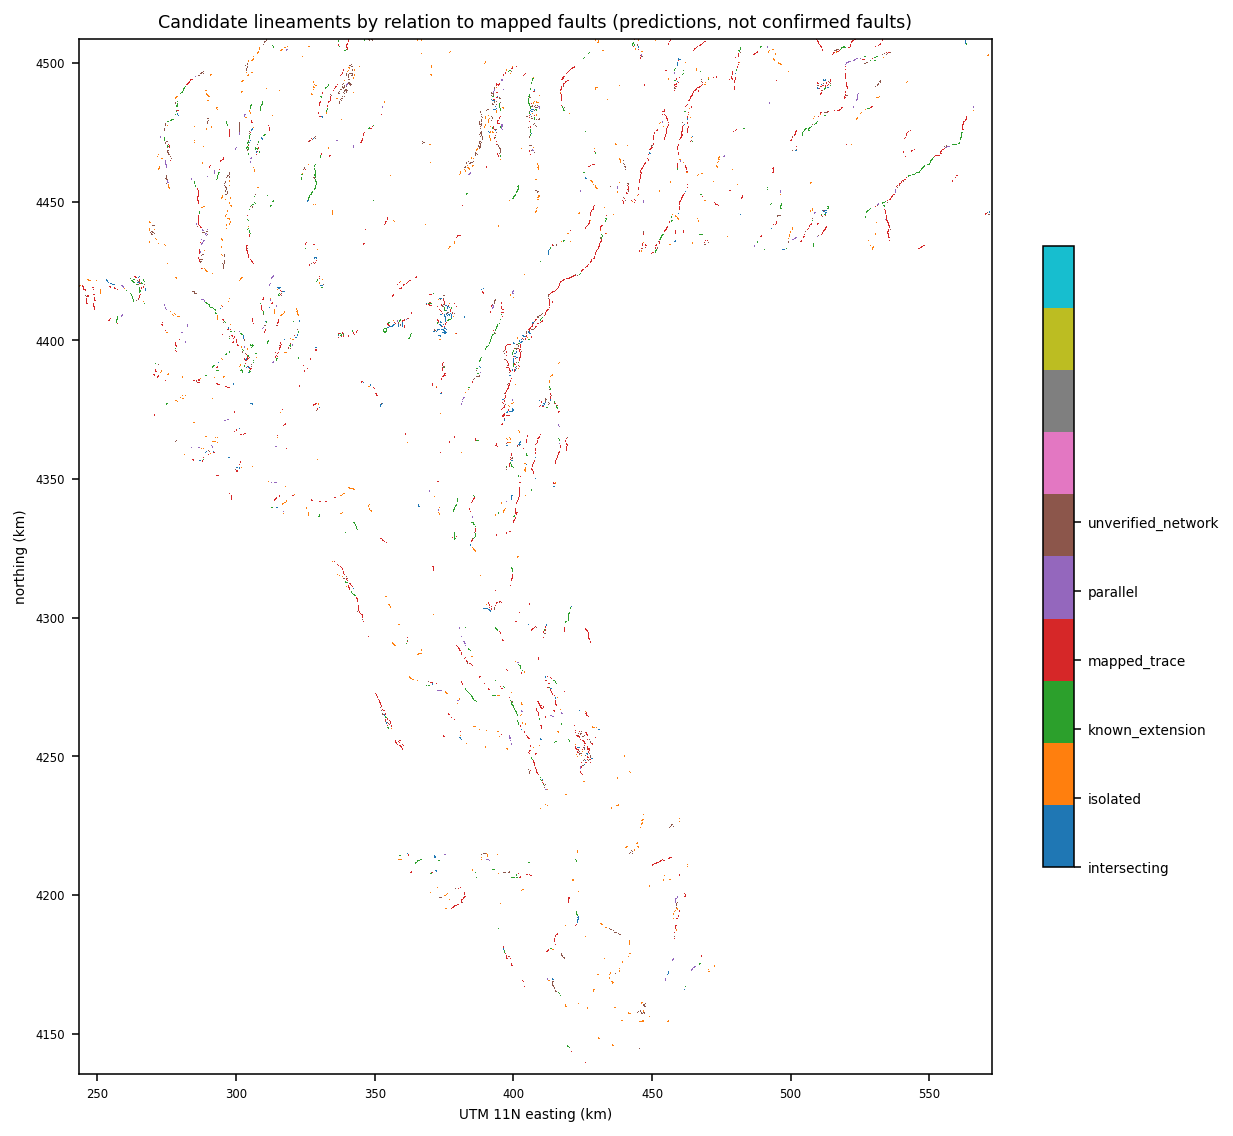

In [15]:
run('topology')
tbl('topology/network_summary.csv'); tbl('topology/candidates.csv', 25)
fig('discovery_atlas')

## 36–37. DTI sensitivity, postprocessing tournament and once-only TEST evaluation
Synthetic experiments show how DTI responds to width, displacement, background, gamma, false-positive length and recall. The tournament scores raw probabilities, output transforms, binary area budgets, crest (NMS) lines, small-component removal, gap linking, regime-balanced budgets, soft outputs and a known-fault ring on every validation unit; each unit's choice is made on the other units, and the full search table is saved. The selected (model, representation) is then evaluated **once** on the untouched TEST fold.

In [ ]:
run('dti_opt')
p = W / 'dti_opt' / 'selection.json'
if p.exists():
    sel = json.loads(p.read_text())
    print('champion model:', sel['champion_model'], '| representation:', sel['key'])
    print('cross-fitted:', {t: round(v['dti_crossfit'], 4) for t, v in sel['crossfit'].items()})
    print('TEST proxy (once):', round(sel['test']['test_proxy_dti'], 4), '-', sel['test']['note'])
tbl('dti_opt/representation_families.csv', 30); tbl('dti_opt/width_displacement.csv')
fig('dti_synthetic_sensitivity', 'dti_vs_area')

[dti_opt] running (no manifest)


## 22 (on held-out predictions). Failure modes and error taxonomy
Missed faults (all / weak archetype), broken continuity, displacement, thick ribbons, isolated noise, false positives on ridges, drainages, nodata boundaries and near known faults, spurious junctions. Each category names the tournament operation or experiment that tests its remedy.

In [ ]:
run('failure_modes')
tbl('failure_modes/taxonomy.csv', 30)
fig('failure_mode_panels')

## 38–40. Submission candidates, final GeoTIFF validation and export
Candidates **A** (safe raw baseline), **B** (best physics model), **C** (discovery champion with the tournament representation). Each is written on the official template grid (float32, [0, 1], NaN outside the template, 0 on pixel-exact known faults, no buffer) and validated (geometry, dtype, NaN pattern, range, non-degenerate, checksum, reopen). The champion is chosen by evidence and copied to `submission_g13_champion.tif` and `predicted_faults.tif`.

In [ ]:
run('submission')
tbl('submissions/candidate_comparison.csv')
p = W / 'submissions' / 'champion.json'
if p.exists():
    ch = json.loads(p.read_text())
    display(Markdown(f"""**Champion:** `{ch['file']}` (candidate {ch['chosen_candidate']}, model `{ch['model']}`)
**Selection:** {ch['selection_rule']}
**Files on Drive:** `{OUT_DIR}/submissions/predicted_faults.tif` (identical copy: `submission_g13_champion.tif`)
**Download:** Drive web UI, or `from google.colab import files; files.download('{WORK_DIR}/submissions/predicted_faults.tif')`
**Submit:** https://www.drivendata.org/competitions/306/competition-doe-gems/ → *Submissions* → upload the file. Nothing is uploaded automatically.
**Leaderboard score:** {ch['leaderboard_score']}"""))

## 41. Leaderboard feedback (manual)
After the platform shows a score, type it in here. It is appended to `submission_history.csv` next to the offline proxies so the proxy–leaderboard gap can be studied. Do not use repeated uploads as a parameter search (3 scored submissions per rolling 7 days).

In [ ]:
SUBMITTED_FILE = ''     # e.g. 'predicted_faults.tif'
PUBLIC_SCORE = None     # the number shown by DrivenData
if SUBMITTED_FILE and PUBLIC_SCORE is not None:
    display(eng.log_leaderboard(SUBMITTED_FILE, float(PUBLIC_SCORE), notes=MODE))
else:
    print('no leaderboard score logged')

## 42. Scientific report and next experiments
Markdown + HTML report with the 15 required sections, findings judged from measured effects (`supported` needs a positive effect, a block-bootstrap interval above zero and a positive sign in every zone), figure index and runtime table.

In [ ]:
run('report')
eng.ws.persist()
display(eng.status())
tbl('reports/findings.csv')
display(Markdown((W / 'reports' / 'report.md').read_text()[:6000]))
print('full report:', OUT_DIR + '/reports/report.html')